--- K-MEANS RESULTS ---
Final Cluster Centers (Standardized):
 [[-0.1933 -0.2259  0.4206 -0.3204 -0.0399 -0.6887 -0.6537]
 [-1.0371 -1.0114 -0.992  -0.8939 -1.1042  0.7868 -0.5972]
 [ 1.2265  1.2357  0.5327  1.2199  1.1304 -0.0468  1.2802]]

--- DBSCAN RESULTS ---
Number of Clusters Formed: 3
Total Number of Noise Points: 59


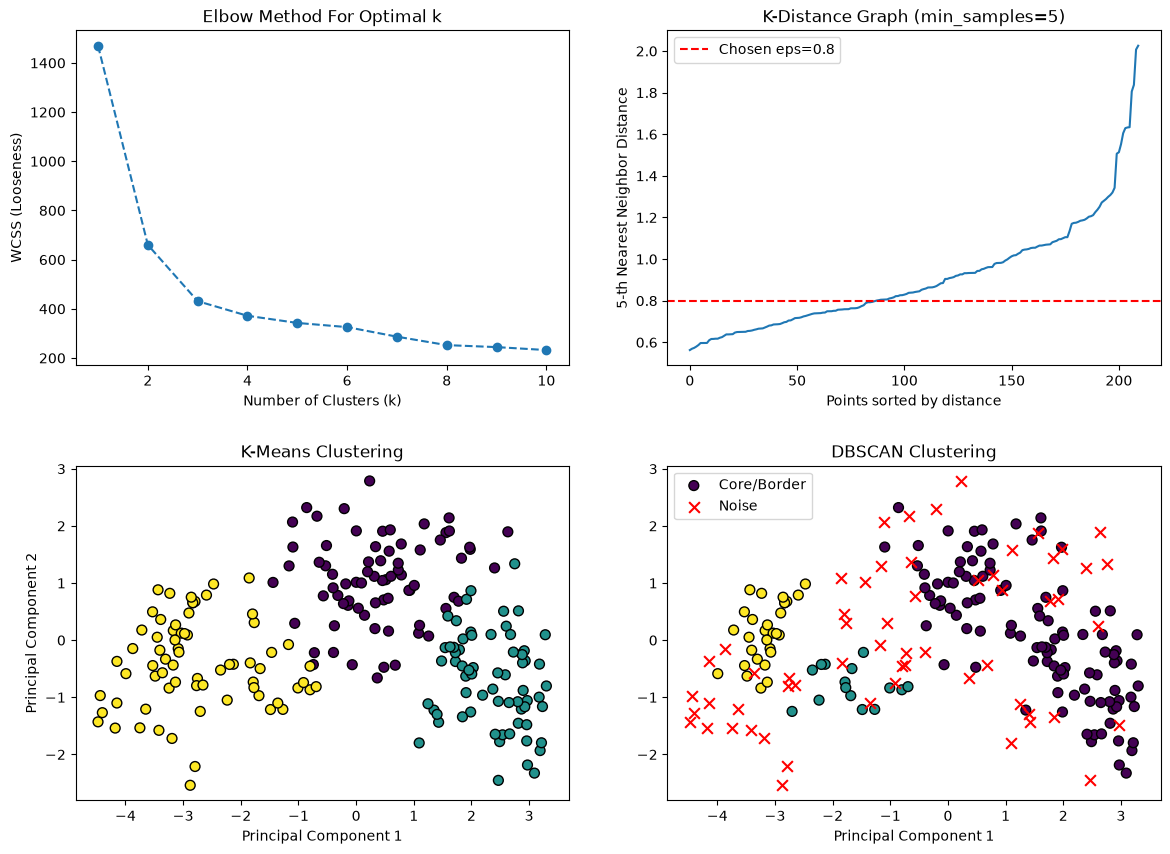


--- EVALUATION AGAINST TRUE LABELS ---
K-Means Purity Score: 0.9381
DBSCAN Purity Score:  0.4905


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def get_distance(point1, point2):
    squared_differences = []
    for i in range(len(point1)):
        difference = point1[i] - point2[i]
        squared_differences.append(difference ** 2)
    sum_of_squares = sum(squared_differences)
    return np.sqrt(sum_of_squares)

def standardize_scratch(X):
    num_rows = X.shape[0]
    num_cols = X.shape[1]
    X_scaled = np.zeros((num_rows, num_cols))
    
    for col in range(num_cols):
        column_data = X[:, col]
        col_mean = np.mean(column_data)
        col_std = np.std(column_data)
        
        for row in range(num_rows):
            X_scaled[row, col] = (X[row, col] - col_mean) / col_std
            
    return X_scaled

class KMeansScratch:
    def __init__(self, k=3, max_iters=100, random_state=42):
        self.k = k
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids = []
        self.labels_ = []
        
    def fit(self, X):
        np.random.seed(self.random_state)
        
        self.centroids = []
        random_indices = np.random.choice(len(X), self.k, replace=False)
        for idx in random_indices:
            self.centroids.append(X[idx])
        self.centroids = np.array(self.centroids)
        
        self.labels_ = np.zeros(len(X))
        
        for iteration in range(self.max_iters):
            for i in range(len(X)):
                min_distance = float('inf')
                closest_centroid_index = 0
                
                for j in range(self.k):
                    dist = get_distance(X[i], self.centroids[j])
                    if dist < min_distance:
                        min_distance = dist
                        closest_centroid_index = j
                        
                self.labels_[i] = closest_centroid_index
                
            old_centroids = self.centroids.copy()
            
            for j in range(self.k):
                points_in_cluster = []
                for i in range(len(X)):
                    if self.labels_[i] == j:
                        points_in_cluster.append(X[i])
                        
                if len(points_in_cluster) > 0:
                    self.centroids[j] = np.mean(points_in_cluster, axis=0)
                    
            if np.array_equal(old_centroids, self.centroids):
                break
                
    def get_wcss(self, X):
        total_wcss = 0.0
        for i in range(len(X)):
            cluster_id = int(self.labels_[i])
            dist = get_distance(X[i], self.centroids[cluster_id])
            total_wcss += (dist ** 2)
        return total_wcss

class DBSCANScratch:
    def __init__(self, eps=0.5, min_samples=5):
        self.eps = eps
        self.min_samples = min_samples
        self.labels_ = []
        
    def fit(self, X):
        n_samples = len(X)
        self.labels_ = np.full(n_samples, -1)
        visited = np.zeros(n_samples, dtype=bool)
        current_cluster_id = 0
        
        for i in range(n_samples):
            if visited[i]:
                continue
                
            visited[i] = True
            
            neighbors = []
            for j in range(n_samples):
                if get_distance(X[i], X[j]) <= self.eps:
                    neighbors.append(j)
                    
            if len(neighbors) < self.min_samples:
                self.labels_[i] = -1
            else:
                self.labels_[i] = current_cluster_id
                
                index = 0
                while index < len(neighbors):
                    neighbor_idx = neighbors[index]
                    
                    if not visited[neighbor_idx]:
                        visited[neighbor_idx] = True
                        
                        new_neighbors = []
                        for j in range(n_samples):
                            if get_distance(X[neighbor_idx], X[j]) <= self.eps:
                                new_neighbors.append(j)
                                
                        if len(new_neighbors) >= self.min_samples:
                            for new_person in new_neighbors:
                                if new_person not in neighbors:
                                    neighbors.append(new_person)
                                    
                    if self.labels_[neighbor_idx] == -1:
                        self.labels_[neighbor_idx] = current_cluster_id
                        
                    index += 1
                    
                current_cluster_id += 1

def pca_scratch(X, n_components=2):
    X_centered = np.zeros_like(X)
    for col in range(X.shape[1]):
        col_mean = np.mean(X[:, col])
        for row in range(X.shape[0]):
            X_centered[row, col] = X[row, col] - col_mean
            
    cov_matrix = np.cov(X_centered, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    sorted_eigenvectors = eigenvectors[:, sorted_indices]
    
    top_eigenvectors = sorted_eigenvectors[:, 0:n_components]
    X_pca = np.dot(X_centered, top_eigenvectors)
    
    return X_pca

def get_k_distances_scratch(X, k=5):
    all_kth_distances = []
    
    for i in range(len(X)):
        distances_for_this_point = []
        for j in range(len(X)):
            dist = get_distance(X[i], X[j])
            distances_for_this_point.append(dist)
            
        distances_for_this_point.sort()
        kth_distance = distances_for_this_point[k]
        all_kth_distances.append(kth_distance)
        
    all_kth_distances.sort()
    return all_kth_distances

def calculate_purity_score(y_true, y_pred):
    correct_guesses = 0
    unique_clusters = np.unique(y_pred)
    
    for cluster_id in unique_clusters:
        if cluster_id == -1:
            continue
            
        labels_in_this_cluster = []
        for i in range(len(y_pred)):
            if y_pred[i] == cluster_id:
                labels_in_this_cluster.append(y_true[i])
                
        if len(labels_in_this_cluster) > 0:
            most_common_label = max(set(labels_in_this_cluster), key=labels_in_this_cluster.count)
            
            for label in labels_in_this_cluster:
                if label == most_common_label:
                    correct_guesses += 1
                    
    total_samples = len(y_true)
    return correct_guesses / total_samples

def main():
    df = pd.read_csv('seeds_data.csv')
    X = df.drop('Class', axis=1).values
    y_true = df['Class'].values
    
    X_scaled = standardize_scratch(X)
    
    wcss_scores = []
    k_range = range(1, 11)
    for k in k_range:
        km = KMeansScratch(k=k, random_state=42)
        km.fit(X_scaled)
        wcss_scores.append(km.get_wcss(X_scaled))
        
    kmeans_model = KMeansScratch(k=3, random_state=42)
    kmeans_model.fit(X_scaled)
    
    print("--- K-MEANS RESULTS ---")
    print("Final Cluster Centers (Standardized):\n", np.round(kmeans_model.centroids, 4))
    
    min_samples = 5
    k_distances = get_k_distances_scratch(X_scaled, k=min_samples)
    
    eps = 0.8
    dbscan_model = DBSCANScratch(eps=eps, min_samples=min_samples)
    dbscan_model.fit(X_scaled)
    
    n_clusters = len(set(dbscan_model.labels_)) - (1 if -1 in dbscan_model.labels_ else 0)
    n_noise = list(dbscan_model.labels_).count(-1)
    
    print("\n--- DBSCAN RESULTS ---")
    print(f"Number of Clusters Formed: {n_clusters}")
    print(f"Total Number of Noise Points: {n_noise}")
    
    X_pca = pca_scratch(X_scaled, n_components=2)
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    plt.subplots_adjust(hspace=0.3)
    
    axes[0, 0].plot(k_range, wcss_scores, marker='o', linestyle='--')
    axes[0, 0].set_title('Elbow Method For Optimal k')
    axes[0, 0].set_xlabel('Number of Clusters (k)')
    axes[0, 0].set_ylabel('WCSS (Looseness)')
    
    axes[0, 1].plot(k_distances)
    axes[0, 1].set_title(f'K-Distance Graph (min_samples={min_samples})')
    axes[0, 1].set_xlabel('Points sorted by distance')
    axes[0, 1].set_ylabel(f'{min_samples}-th Nearest Neighbor Distance')
    axes[0, 1].axhline(y=eps, color='r', linestyle='--', label=f'Chosen eps={eps}')
    axes[0, 1].legend()
    
    axes[1, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_model.labels_, cmap='viridis', edgecolor='k', s=50)
    axes[1, 0].set_title('K-Means Clustering')
    axes[1, 0].set_xlabel('Principal Component 1')
    axes[1, 0].set_ylabel('Principal Component 2')
    
    mask_noise = dbscan_model.labels_ == -1
    mask_core = dbscan_model.labels_ != -1
    axes[1, 1].scatter(X_pca[mask_core, 0], X_pca[mask_core, 1], c=np.array(dbscan_model.labels_)[mask_core], 
                       cmap='viridis', edgecolor='k', s=50, label='Core/Border')
    axes[1, 1].scatter(X_pca[mask_noise, 0], X_pca[mask_noise, 1], c='red', marker='x', 
                       s=60, label='Noise')
    axes[1, 1].set_title('DBSCAN Clustering')
    axes[1, 1].set_xlabel('Principal Component 1')
    axes[1, 1].legend()
    
    plt.show()
    
    kmeans_purity = calculate_purity_score(y_true, kmeans_model.labels_)
    dbscan_purity = calculate_purity_score(y_true, dbscan_model.labels_)
    
    print("\n--- EVALUATION AGAINST TRUE LABELS ---")
    print(f"K-Means Purity Score: {kmeans_purity:.4f}")
    print(f"DBSCAN Purity Score:  {dbscan_purity:.4f}")

if __name__ == "__main__":
    main()